# Employee Sentiment Analysis

**Goal:** assess employee sentiment and engagement from an unlabeled dataset of employee e-mails (`test.csv`).

| Task | What this notebook does | Supporting module |
|---|---|---|
| 1. Sentiment labeling | Label every message Positive / Negative / Neutral | `src/sentiment.py` |
| 2. EDA | Structure, distributions, trends, anomalies, charts | `src/eda.py`, `src/visualization.py` |
| 3. Employee score | Monthly score per employee (+1 / −1 / 0, resets monthly) | `src/scoring.py` |
| 4. Ranking | Top-3 positive and top-3 negative employees per month | `src/scoring.py` |
| 5. Flight risk | ≥ 4 negative messages within any rolling 30-day window | `src/flight_risk.py` |
| 6. Predictive model | scikit-learn linear regression of the monthly score | `src/modeling.py` |

All processing happens in this notebook; the `src/` modules only hold the reusable functions so that each step is short, testable (`tests/`) and reproducible (`python run_pipeline.py` produces the identical outputs from the raw CSV).

## 0. Setup

In [1]:
import json, warnings
import pandas as pd
from IPython.display import Image, Markdown, display
show = lambda text: display(Markdown(text))

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from src import config as C
from src import preprocessing, sentiment, eda, scoring, flight_risk, modeling, findings
from src import visualization as viz

print("Raw data      :", C.RAW_DATA_PATH)
print("Labeling with :", C.SENTIMENT_METHOD)

Raw data      : C:\dev\employee-sentiment-analysis\data\raw\test.csv
Labeling with : transformer


## 1. Load and clean the data

The raw file has four columns: `Subject`, `body`, `date`, `from` (the employee). The bodies are Enron e-mails exported with
**quoted-printable artifacts** (`=20` = space, `=` + newline = soft line break, `=01)` = control byte). These are pure noise for an NLP model,
so `preprocessing.clean_text` decodes them, drops forwarded / quoted history, URLs and e-mail addresses, and collapses whitespace.
The original `body` is kept untouched for traceability; the model reads `clean_text` = subject + cleaned body.

In [2]:
raw = preprocessing.load_raw()
df = preprocessing.prepare(raw)
print(raw.shape)
raw.head()

(2191, 4)


,Subject,body,date,from
0,EnronOptions Update!,EnronOptions Announcement\n\n\nWe have updated...,2010-05-10,sally.beck@enron.com
1,(No Subject),"Marc,\n\nUnfortunately, today is not going to ...",2010-07-29,eric.bass@enron.com
2,Phone Screen Interview - Shannon L. Burnham,"When: Wednesday, June 06, 2001 10:00 AM-11:00 ...",2011-07-25,sally.beck@enron.com
3,RE: My new work email,we were thinking papasitos (we can meet somewh...,2010-03-25,johnny.palmer@enron.com
4,Bet,Since you never gave me the $20 for the last t...,2011-05-21,lydia.delgado@enron.com


In [3]:
# before / after cleaning for one message
i = df["body"].str.contains("=20").idxmax()
print("RAW  :", df.loc[i, "body"][:300].replace("\n", " | "))
print()
print("CLEAN:", df.loc[i, "clean_text"][:300])

RAW  : EnronOptions Announcement |  |  | We have updated the EnronOptions =01) Your Stock Option Program web site!  = | The=20 | web site now contains specific details of the EnronOptions Program includin= | g=20 | the December 29, 2000 grant price and additional information on employee=20 | eligibility. |  | Access EnronOpti

CLEAN: EnronOptions Update!. EnronOptions Announcement We have updated the EnronOptions ) Your Stock Option Program web site! The web site now contains specific details of the EnronOptions Program including the December 29, 2000 grant price and additional information on employee eligibility. Access EnronOp


## 2. Task 1 — Sentiment labeling

**Approach.** The brief prefers a large language model (LLM) or any suitable NLP technique. `src/sentiment.py` implements three interchangeable back-ends behind one function, selected with `SENTIMENT_METHOD` in `.env`:

| Back-end | When to use | Reproducibility |
|---|---|---|
| `llm` (Claude / GPT, zero-shot prompt, temperature 0) | Highest semantic accuracy: judges the sender's intent, not individual words | Every label cached in `data/llm_cache.csv`, so reruns need no API key |
| `vader` | Offline, no API key, no GPU | Fully deterministic |
| `transformer` (RoBERTa sentiment model) | Better context handling than a lexicon; needs `transformers` + `torch` | Deterministic |

**LLM labeling rule:** a fixed prompt (`sentiment.LLM_PROMPT`, printed below) defines the three classes:
- **Positive:** appreciation, enthusiasm, satisfaction, good news.
- **Negative:** frustration, complaints, criticism, worry, bad news, conflict.
- **Neutral:** purely informational or logistical content.

The reply is parsed to one label, and anything unparseable becomes Neutral.

**VADER labeling rule** (Hutto & Gilbert 2014): `compound ≥ 0.05 → Positive`, `compound ≤ −0.05 → Negative`, otherwise `Neutral`.

The method actually used is printed by the next cell.

In [4]:
print("Labeling method:", C.SENTIMENT_METHOD)
if C.SENTIMENT_METHOD == "llm":
    print(sentiment.LLM_PROMPT)

Labeling method: transformer


In [5]:
df = sentiment.label_messages(df)          # adds `sentiment` and `sentiment_score_raw`
df = scoring.add_message_scores(df)        # +1 / -1 / 0 per message
df.drop(columns=["clean_body"]).to_csv(C.LABELED_PATH, index=False)
df[["from", "date", "Subject", "sentiment_score_raw", "sentiment"]].head(10)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,from,date,Subject,sentiment_score_raw,sentiment
0,johnny.palmer@enron.com,2010-01-01,ERCOT Readiness Update attached,0.858940,Neutral
1,eric.bass@enron.com,2010-01-02,RE: data,0.869476,Neutral
2,lydia.delgado@enron.com,2010-01-02,Re: Wellhead Accrual Income,0.940430,Neutral
3,don.baughman@enron.com,2010-01-02,(No Subject),0.844057,Neutral
4,lydia.delgado@enron.com,2010-01-02,Tiger recruiting #1,0.590138,Positive
5,eric.bass@enron.com,2010-01-02,Doorstep meeting 8/4 New time - 9:30 AM,0.915449,Neutral
6,eric.bass@enron.com,2010-01-03,Re: Jordan's comments on Doorstep meeting,0.900726,Positive
7,kayne.coulter@enron.com,2010-01-03,RE: Trade,0.809711,Neutral
8,don.baughman@enron.com,2010-01-03,Re: Happy Hour,0.744949,Negative
9,eric.bass@enron.com,2010-01-03,computer wallpaper- must have,0.843186,Neutral


In [6]:
# sanity check: example messages of each class (strongest VADER scores, or a random sample for LLM labels)
for lab in ["Positive", "Negative", "Neutral"]:
    sub = df[df.sentiment == lab]
    if sub["sentiment_score_raw"].notna().any():
        sub = sub.sort_values("sentiment_score_raw", ascending=(lab == "Negative"))
    else:
        sub = sub.sample(min(3, len(sub)), random_state=0)
    print(f"--- {lab} examples ---")
    for t in sub["clean_text"].head(3):
        print("•", t[:180])

--- Positive examples ---
• Congratulations!. Congratulations on your promotion to Vice President! Well deserved and a nice way to cap off your stay in London. I look forward to celebrating with you in London
• Promotion. Sally, I am so excited for you and your promotion. I have had the privilege to see the impact you have made on this organization, and I am very glad to see you get the r
• Promotion. Sally, I am so excited for you and your promotion. I have had the privilege to see the impact you have made on this organization, and I am very glad to see you get the r
--- Negative examples ---
• Re: Got caught up with real time issue - missed my slot today. I was probably hopelessly stuck in traffic when we were to talk, and did not even realize that the time had passed. C
• Re: Got caught up with real time issue - missed my slot today. I was probably hopelessly stuck in traffic when we were to talk, and did not even realize that the time had passed. C
• Re: Got caught up with real tim

In [7]:
# Data-integrity validation after cleaning + labeling
assert len(df) == len(raw), "no message may be dropped"
assert df["sentiment"].isin(["Positive", "Negative", "Neutral"]).all(), "every message has a valid label"
assert df["sentiment"].notna().all() and df["date"].notna().all()
assert set(df["from"]) == set(raw["from"].str.strip().str.lower()), "employee set preserved"
print("Integrity checks passed:", len(df), "messages,", df["from"].nunique(), "employees, all labeled")

Integrity checks passed: 2191 messages, 10 employees, all labeled


### Observations
_Generated from the data by `src/findings.py`, so they stay correct for any labeling method._

In [8]:
show(findings.labeling_md(df))

* Labeling method: **a RoBERTa transformer (cardiffnlp/twitter-roberta-base-sentiment-latest)**.
* 2,191 messages labeled: **520 Positive (23.7%)**, **1,524 Neutral (69.6%)**, **147 Negative (6.7%)**.
* The dominant class is **Neutral**. The corpus is mostly routine business correspondence, so polite and informational messages far outnumber complaints.
* 70 messages have an empty body. They are labeled from their subject line, which is why the subject is part of the analysed text.

## 3. Task 2 — Exploratory Data Analysis

### 3.1 Structure, data types and missing values

In [9]:
print(json.dumps(eda.overview(df, raw), indent=2))
eda.structure(raw)

{
  "records": 2191,
  "columns": [
    "Subject",
    "body",
    "date",
    "from"
  ],
  "duplicate_rows": 0,
  "employees": 10,
  "date_min": "2010-01-01",
  "date_max": "2011-12-31",
  "months": 24,
  "median_words": 27.0,
  "empty_bodies": 70
}


,dtype,non_null,missing,unique
Subject,str,2191,0,1251
body,str,2191,0,1539
date,str,2191,0,690
from,str,2191,0,10


### 3.2 Distribution of sentiment labels

,count,share
sentiment,,
Positive,520,0.237
Neutral,1524,0.696
Negative,147,0.067


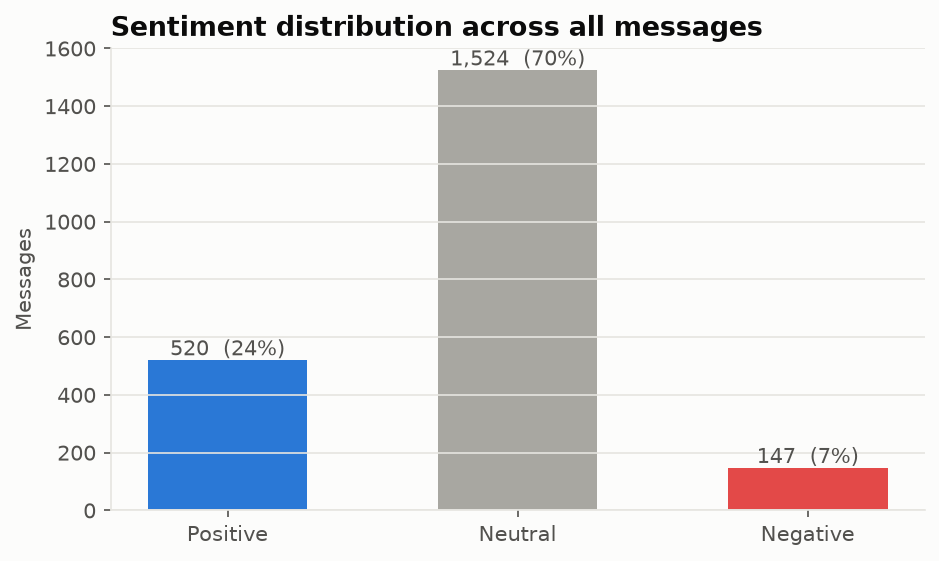

In [10]:
display(eda.sentiment_counts(df))
display(Image(viz.sentiment_distribution(df)))

### 3.3 Trends over time

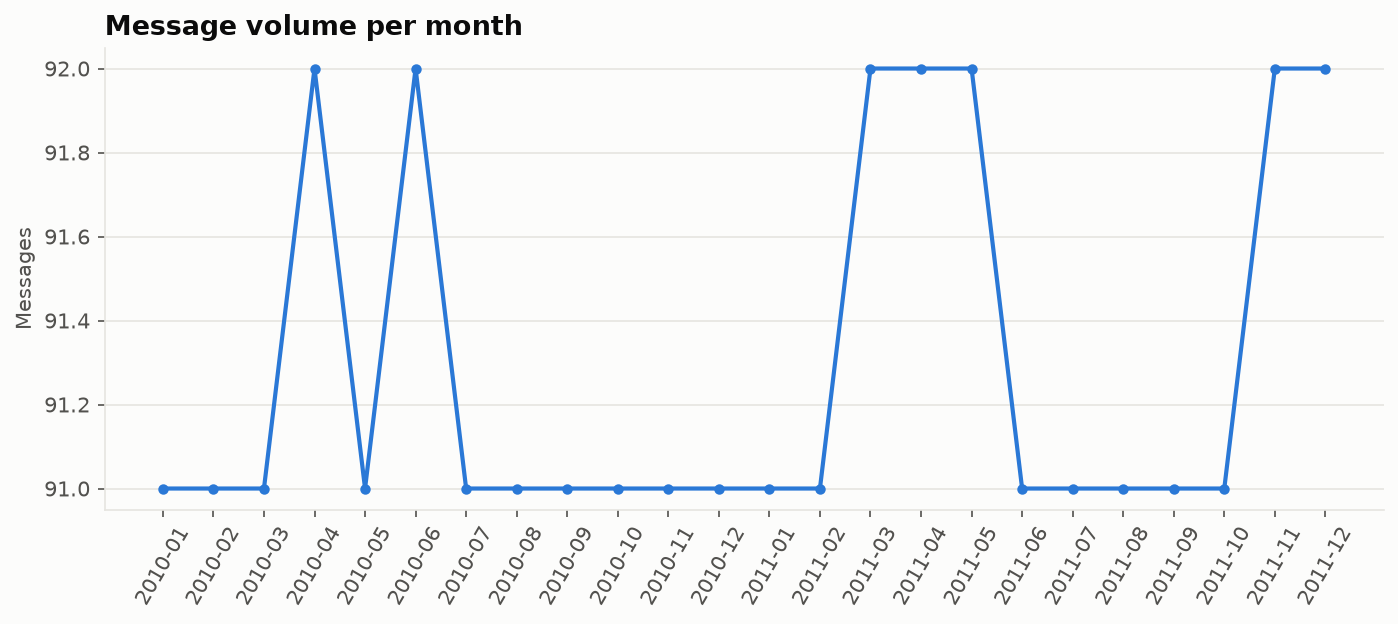

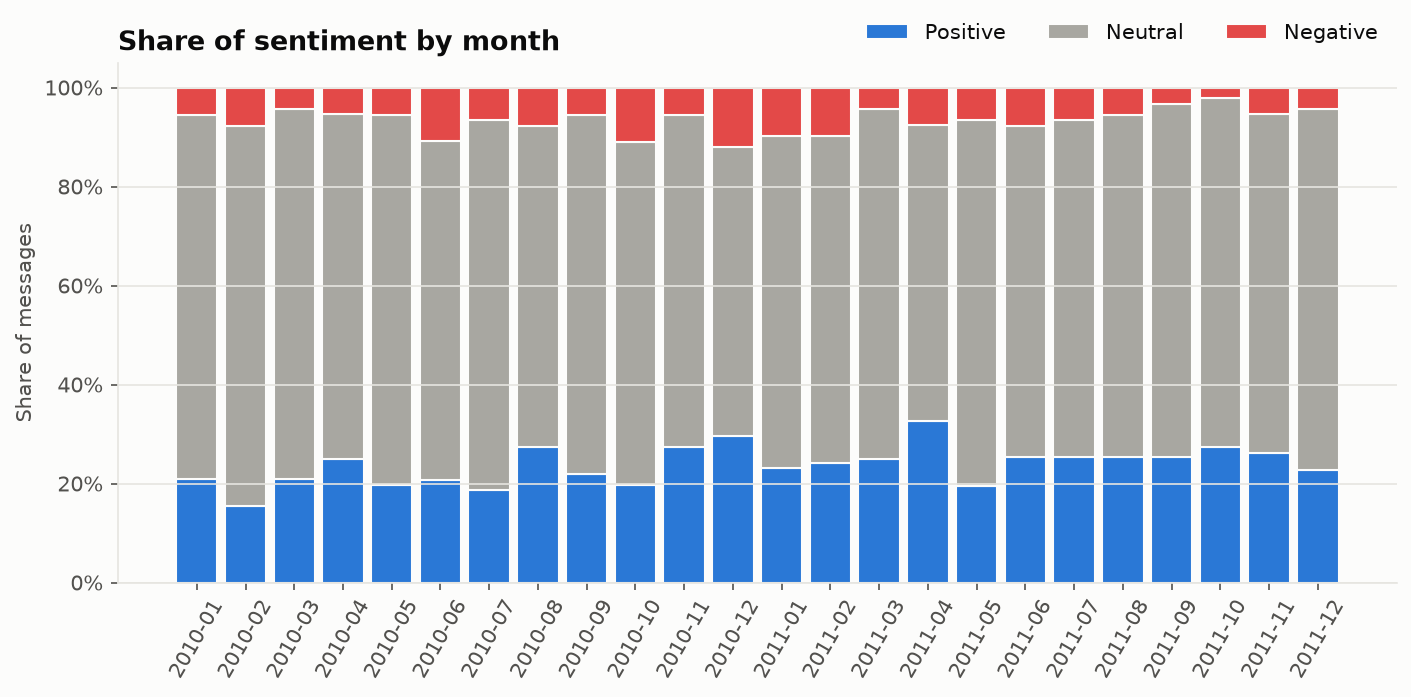

sentiment,Positive,Neutral,Negative,avg_score
year,,,,
2010,244,770,80,0.150
2011,276,754,67,0.191


In [11]:
display(Image(viz.messages_per_month(df)))
display(Image(viz.sentiment_over_time(df)))
eda.yearly_sentiment(df)

### 3.4 Employees, message length and weekly patterns

sentiment,Positive,Neutral,Negative,total,negative_share
from,,,,,
lydia.delgado@enron.com,68,199,17,284,0.060
john.arnold@enron.com,46,187,23,256,0.090
sally.beck@enron.com,63,147,17,227,0.075
patti.thompson@enron.com,50,158,17,225,0.076
bobette.riner@ipgdirect.com,64,133,20,217,0.092
don.baughman@enron.com,38,165,10,213,0.047
johnny.palmer@enron.com,63,139,11,213,0.052
eric.bass@enron.com,54,148,8,210,0.038
kayne.coulter@enron.com,44,118,12,174,0.069


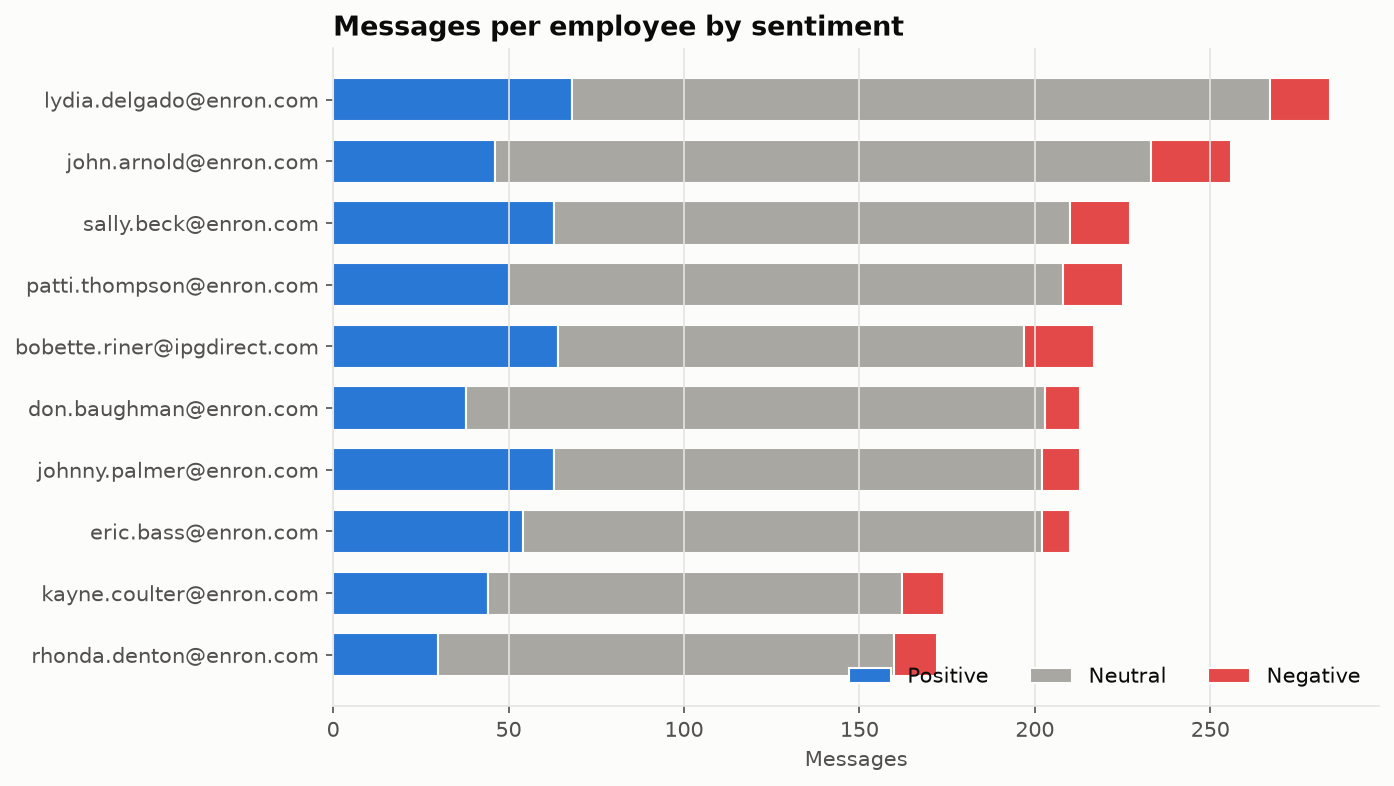

In [12]:
display(eda.per_employee(df))
display(Image(viz.messages_per_employee(df)))

,word_count,char_length
sentiment,,
Positive,32.0,173.0
Neutral,27.0,162.0
Negative,19.0,102.0


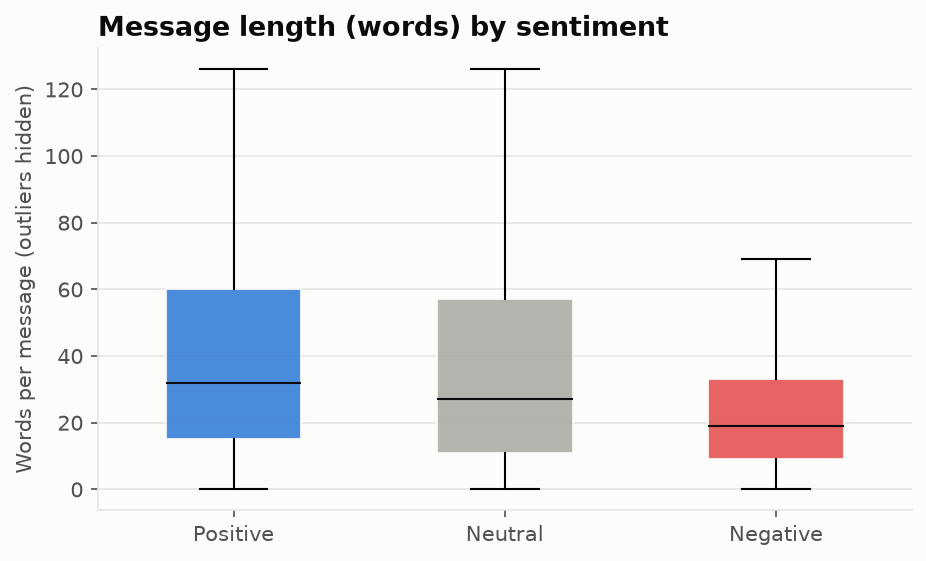

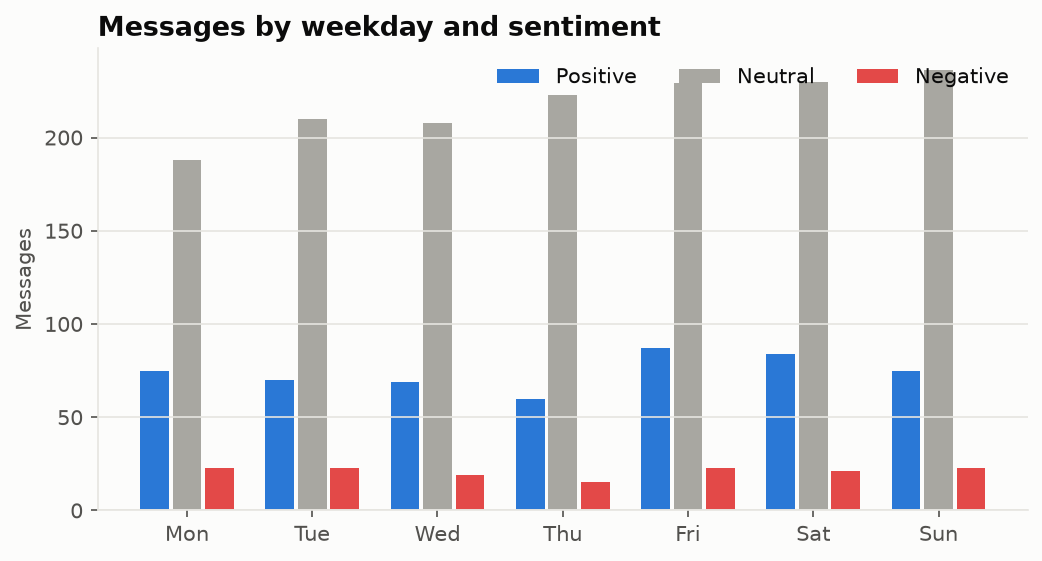

In [13]:
display(eda.length_stats(df))
display(Image(viz.length_by_sentiment(df)))
display(Image(viz.weekday_pattern(df)))

### EDA — key findings

In [14]:
show(findings.eda_md(df, raw))

* **Structure:** 2,191 rows × 4 columns (`Subject`, `body`, `date`, `from`); **no missing values**; 0 fully duplicated rows. `date` is parsed to datetime.
* **Coverage:** 10 employees, 24 months (2010-01-01 to 2011-12-31), and every employee is active in every month.
* **Anomaly:** Monthly volume is almost perfectly flat (91–92 messages per month); 30.5% of messages fall on weekends, about the same rate as weekdays. Real e-mail traffic is rarely this uniform, so the dates appear to have been **assigned synthetically**. Time-based conclusions should be read with caution.
* **Anomaly:** 625 messages repeat an earlier subject + body on a different date. They are kept because each row is a distinct sent message, but they inflate some employees' counts.
* **Trend:** the mean message score moves from 0.15 (2010) to 0.19 (2011).
* **Employees:** activity ranges from 172 (rhonda.denton@enron.com) to 284 messages (lydia.delgado@enron.com). Highest negative share: bobette.riner@ipgdirect.com (9.2%), john.arnold@enron.com (9.0%), patti.thompson@enron.com (7.6%). Lowest: eric.bass@enron.com (3.8%).
* **Length:** Positive messages are the longest (median 32 words) and Negative the shortest (median 19 words).

## 4. Task 3 — Monthly employee sentiment score

**Method.** Each message gets `Positive = +1`, `Negative = −1`, `Neutral = 0`. Messages are grouped by **(employee, calendar month)**,
where the month is the message date truncated to `YYYY-MM`, and the contributions are **summed**. Because every month is its own group,
the score starts from 0 at the beginning of each month (the required reset); nothing carries over. Months in which an employee sent no
messages simply have no row (the heatmap shows them as 0).

In [15]:
scores = scoring.monthly_scores(df)
scores.to_csv(C.MONTHLY_SCORES_PATH, index=False)
print(scores.shape)
display(scores.head(12))
scores["monthly_score"].describe()

(240, 7)


,employee,month,monthly_score,message_count,positive_count,negative_count,neutral_count
0,bobette.riner@ipgdirect.com,2010-01,0,2,0,0,2
1,don.baughman@enron.com,2010-01,2,9,3,1,5
2,eric.bass@enron.com,2010-01,4,10,4,0,6
3,john.arnold@enron.com,2010-01,-1,7,0,1,6
4,johnny.palmer@enron.com,2010-01,1,6,1,0,5
5,kayne.coulter@enron.com,2010-01,4,22,4,0,18
6,lydia.delgado@enron.com,2010-01,2,13,3,1,9
7,patti.thompson@enron.com,2010-01,2,10,3,1,6
8,rhonda.denton@enron.com,2010-01,0,3,0,0,3
9,sally.beck@enron.com,2010-01,0,9,1,1,7


count    240.000000
mean       1.554167
std        1.817276
min       -3.000000
25%        0.000000
50%        1.000000
75%        3.000000
max        8.000000
Name: monthly_score, dtype: float64

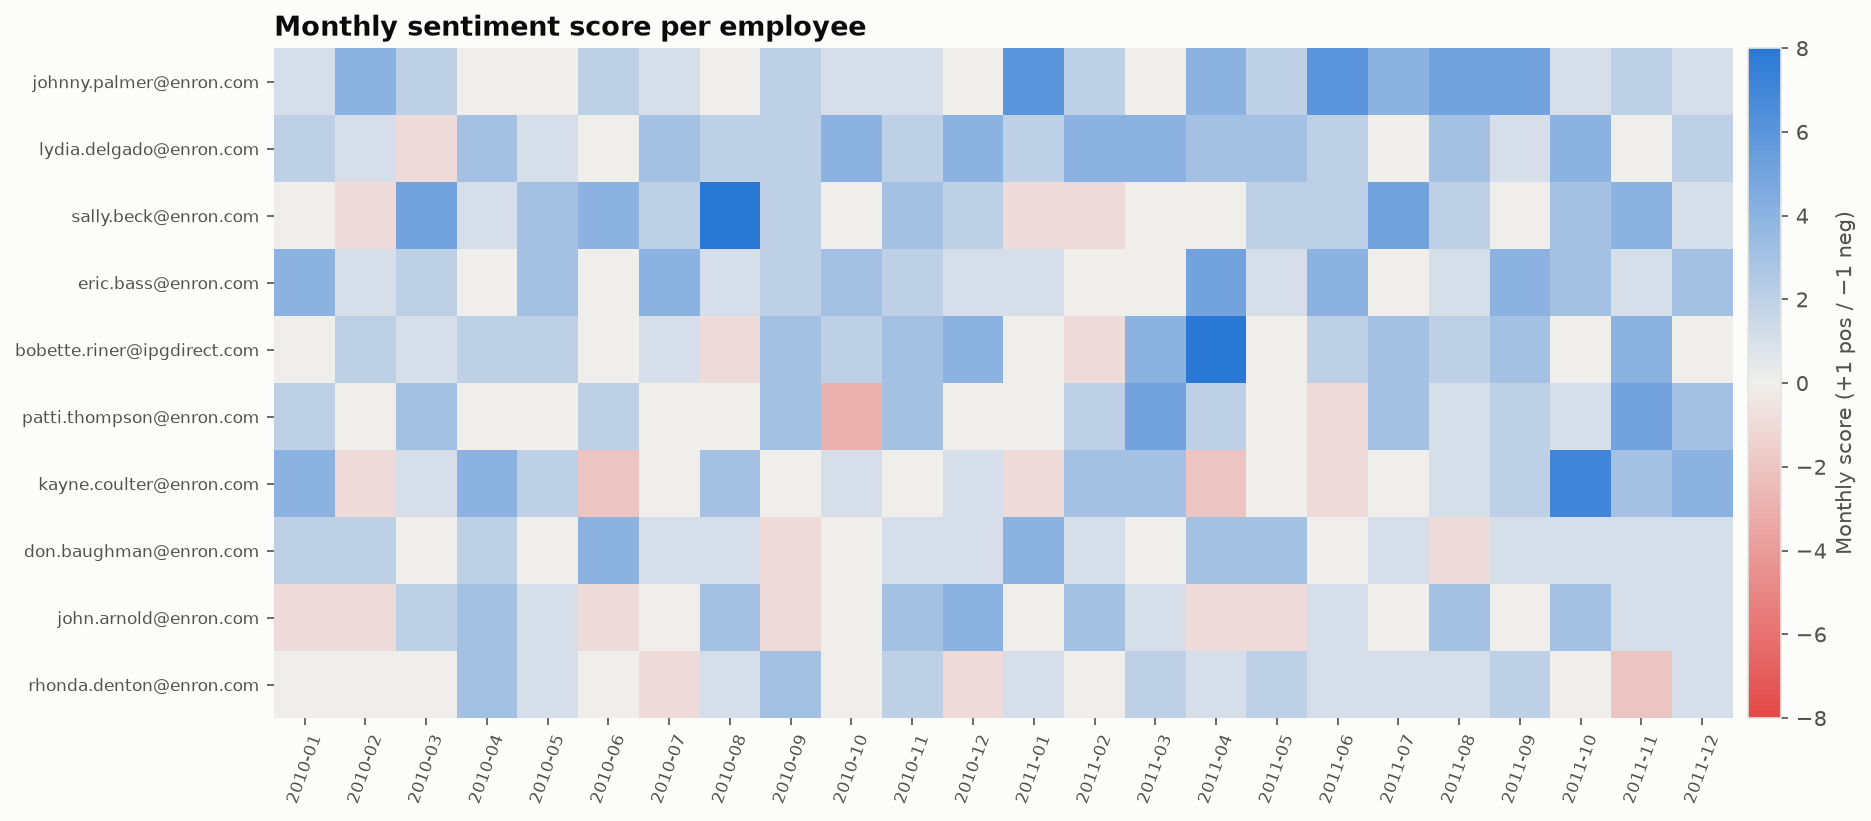

In [16]:
# validation: monthly scores must add up to the per-message total
assert scores["monthly_score"].sum() == df["message_score"].sum()
assert (scores["positive_count"] - scores["negative_count"] == scores["monthly_score"]).all()
display(Image(viz.score_heatmap(scores)))

### Observations

In [17]:
show(findings.scoring_md(scores))

* Monthly scores range from **-3 to 8** (mean 1.6, median 1.0).
* **78 of 240 employee-months are ≤ 0.** The most frequent is john.arnold@enron.com with 11 (2010-01, 2010-02, 2010-06, 2010-07, 2010-09, 2010-10, 2011-01, 2011-04, 2011-05, 2011-07, 2011-09).
* The validation asserts confirm that no message was lost or double-counted in the aggregation, and that score = positives − negatives in every month.

## 5. Task 4 — Employee ranking

**Method.** For each month, using the Task 3 scores:
* **Top 3 positive** — sort by `monthly_score` **descending**, then by employee name **alphabetically** to break ties.
* **Top 3 negative** — sort by `monthly_score` **ascending** (most negative first), then alphabetically.

In [18]:
rankings = scoring.monthly_rankings(scores)
rankings.to_csv(C.RANKINGS_PATH, index=False)

# wide, readable table: one row per month
wide = (rankings.assign(entry=lambda r: r.employee + " (" + r.monthly_score.astype(str) + ")")
        .pivot_table(index="month", columns=["list_type", "rank"], values="entry", aggfunc="first"))
wide

list_type                      Top Negative                                                                                       Top Positive  \
rank                                      1                                2                                3                                1   
month                                                                                                                                            
2010-01          john.arnold@enron.com (-1)  bobette.riner@ipgdirect.com (0)      rhonda.denton@enron.com (0)          eric.bass@enron.com (4)   
2010-02          john.arnold@enron.com (-1)     kayne.coulter@enron.com (-1)        sally.beck@enron.com (-1)      johnny.palmer@enron.com (4)   
2010-03        lydia.delgado@enron.com (-1)       don.baughman@enron.com (0)      rhonda.denton@enron.com (0)         sally.beck@enron.com (5)   
2010-04             eric.bass@enron.com (0)      johnny.palmer@enron.com (0)     patti.thompson@enron.com (0)      kayne.coulter@enron.com (4)   
2010-05          don.baughman@enron.com (0)      johnny.palmer@enron.com (0)     patti.thompson@enron.com (0)          eric.bass@enron.com (3)   
2010-06        kayne.coulter@enron.com (-2)       john.arnold@enron.com (-1)  bobette.riner@ipgdirect.com (0)       don.baughman@enron.com (4)   
2010-07        rhonda.denton@enron.com (-1)        john.arnold@enron.com (0)      kayne.coulter@enron.com (0)          eric.bass@enron.com (4)   
2010-08    bobette.riner@ipgdirect.com (-1)      johnny.palmer@enron.com (0)     patti.thompson@enron.com (0)         sally.beck@enron.com (8)   
2010-09         don.baughman@enron.com (-1)       john.arnold@enron.com (-1)      kayne.coulter@enron.com (0)  bobette.riner@ipgdirect.com (3)   
2010-10       patti.thompson@enron.com (-3)       don.baughman@enron.com (0)        john.arnold@enron.com (0)      lydia.delgado@enron.com (4)   
2010-11         kayne.coulter@enron.com (0)       don.baughman@enron.com (1)      johnny.palmer@enron.com (1)  bobette.riner@ipgdirect.com (3)   
2010-12        rhonda.denton@enron.com (-1)      johnny.palmer@enron.com (0)     patti.thompson@enron.com (0)  bobette.riner@ipgdirect.com (4)   
2011-01        kayne.coulter@enron.com (-1)        sally.beck@enron.com (-1)  bobette.riner@ipgdirect.com (0)      johnny.palmer@enron.com (6)   
2011-02    bobette.riner@ipgdirect.com (-1)        sally.beck@enron.com (-1)          eric.bass@enron.com (0)      lydia.delgado@enron.com (4)   
2011-03          don.baughman@enron.com (0)          eric.bass@enron.com (0)      johnny.palmer@enron.com (0)     patti.thompson@enron.com (5)   
2011-04        kayne.coulter@enron.com (-2)       john.arnold@enron.com (-1)         sally.beck@enron.com (0)  bobette.riner@ipgdirect.com (8)   
2011-05          john.arnold@enron.com (-1)  bobette.riner@ipgdirect.com (0)      kayne.coulter@enron.com (0)       don.baughman@enron.com (3)   
2011-06        kayne.coulter@enron.com (-1)    patti.thompson@enron.com (-1)       don.baughman@enron.com (0)      johnny.palmer@enron.com (6)   
2011-07             eric.bass@enron.com (0)        john.arnold@enron.com (0)      kayne.coulter@enron.com (0)         sally.beck@enron.com (5)   
2011-08         don.baughman@enron.com (-1)          eric.bass@enron.com (1)      kayne.coulter@enron.com (1)      johnny.palmer@enron.com (5)   
2011-09           john.arnold@enron.com (0)         sally.beck@enron.com (0)       don.baughman@enron.com (1)      johnny.palmer@enron.com (5)   
2011-10     bobette.riner@ipgdirect.com (0)      rhonda.denton@enron.com (0)       don.baughman@enron.com (1)      kayne.coulter@enron.com (7)   
2011-11        rhonda.denton@enron.com (-2)      lydia.delgado@enron.com (0)       don.baughman@enron.com (1)     patti.thompson@enron.com (5)   
2011-12     bobette.riner@ipgdirect.com (0)       don.baughman@enron.com (1)        john.arnold@enron.com (1)      kayne.coulter@enron.com (4)   

list_type                                                

Latest month: 2011-12


,employee,monthly_score
0,kayne.coulter@enron.com,4
1,eric.bass@enron.com,3
2,patti.thompson@enron.com,3


,employee,monthly_score
0,bobette.riner@ipgdirect.com,0
1,don.baughman@enron.com,1
2,john.arnold@enron.com,1


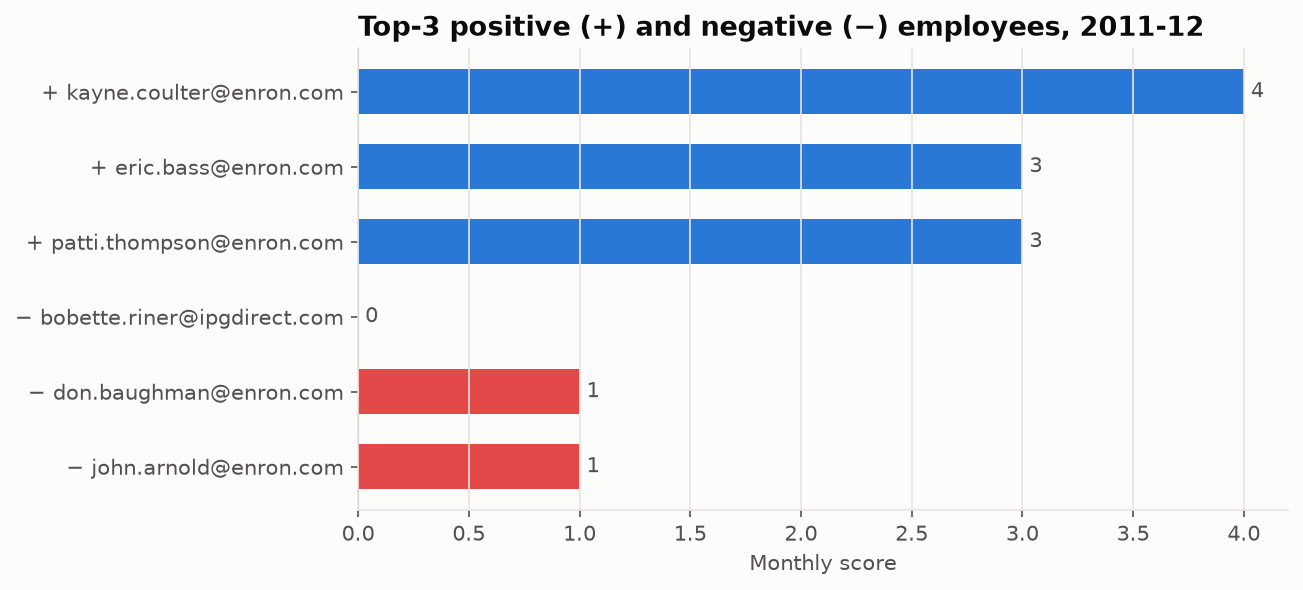

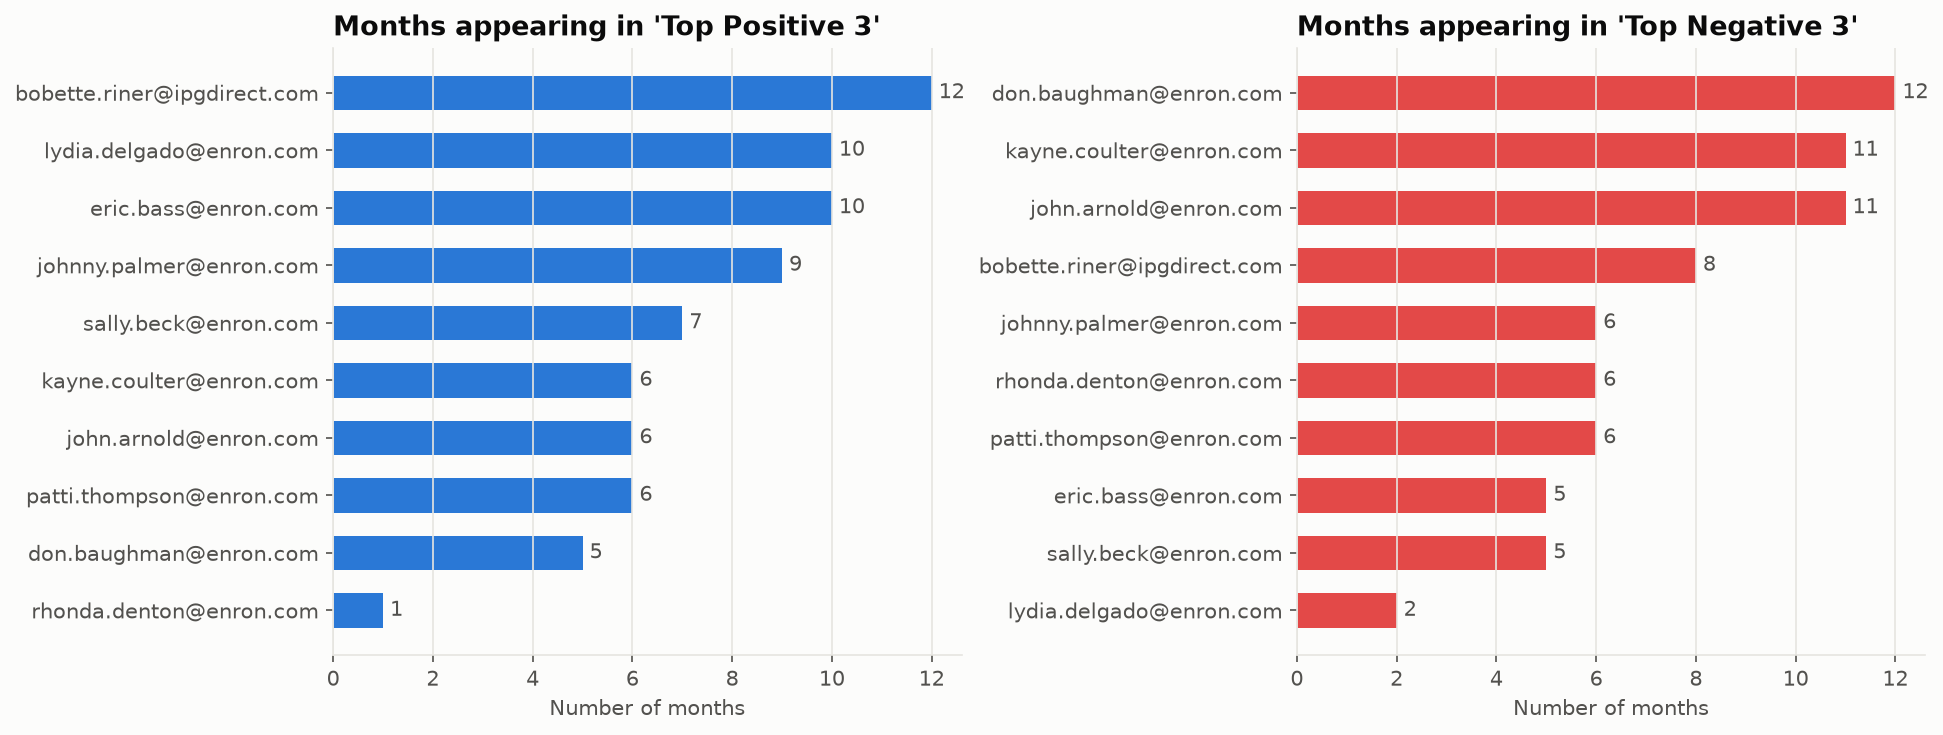

In [19]:
latest = sorted(scores.month.unique())[-1]
top_pos, top_neg = scoring.rank_month(scores, latest)
print("Latest month:", latest)
display(top_pos[["employee", "monthly_score"]].reset_index(drop=True))
display(top_neg[["employee", "monthly_score"]].reset_index(drop=True))
display(Image(viz.latest_month_ranking(scores, latest)))
display(Image(viz.ranking_frequency(rankings)))

In [20]:
# whole-period view: sum of all monthly scores
scoring.overall_ranking(scores)

,employee,total_score
0,johnny.palmer@enron.com,52
1,lydia.delgado@enron.com,51
2,eric.bass@enron.com,46
3,sally.beck@enron.com,46
4,bobette.riner@ipgdirect.com,44
5,patti.thompson@enron.com,33
6,kayne.coulter@enron.com,32
7,don.baughman@enron.com,28
8,john.arnold@enron.com,23
9,rhonda.denton@enron.com,18


### Observations

In [21]:
show(findings.ranking_md(scores, rankings))

* **Latest month (2011-12):** top positive: kayne.coulter@enron.com (4), eric.bass@enron.com (3), patti.thompson@enron.com (3). Top negative: bobette.riner@ipgdirect.com (0), don.baughman@enron.com (1), john.arnold@enron.com (1). Ties are broken alphabetically.
* **Consistency across 24 months:** bobette.riner@ipgdirect.com is in the monthly top-3 positive most often (12 months). don.baughman@enron.com appears in the top-3 negative most often (12 months).
* Rankings partly reflect volume: the score is a sum, so prolific writers rank higher. The whole-period leader is johnny.palmer@enron.com (+52).

## 6. Task 5 — Flight risk identification

**Definition (from the brief):** an employee is a flight risk if they sent **4 or more negative messages within any rolling 30-day period**,
regardless of calendar month and regardless of their score.

**Method.** For each employee, take the sorted dates of their Negative messages and slide a window: if any 4 consecutive negatives
fit inside one 30-day span (first and fourth at most 29 days apart, i.e. day *d* … day *d+29*), the employee is flagged. This catches
bursts that straddle a month boundary, which a per-month count would miss. The boundary is covered by unit tests in `tests/test_logic.py`.

In [22]:
windows = flight_risk.find_risk_windows(df)
risk = flight_risk.flight_risk_employees(df, windows)
windows.to_csv(C.FLIGHT_RISK_WINDOWS_PATH, index=False)
risk.to_csv(C.FLIGHT_RISK_PATH, index=False)
print(f"{len(risk)} employee(s) flagged as flight risk")
risk

4 employee(s) flagged as flight risk


,employee,max_negatives_in_30d,first_flagged_window_start,qualifying_windows,total_negative_messages
0,john.arnold@enron.com,4,2010-06-06,2,23
1,patti.thompson@enron.com,4,2010-10-04,1,17
2,rhonda.denton@enron.com,4,2010-12-24,1,12
3,sally.beck@enron.com,4,2010-12-15,1,17


Calendar-month method would flag: 2
Only caught by the rolling window: ['rhonda.denton@enron.com', 'sally.beck@enron.com']


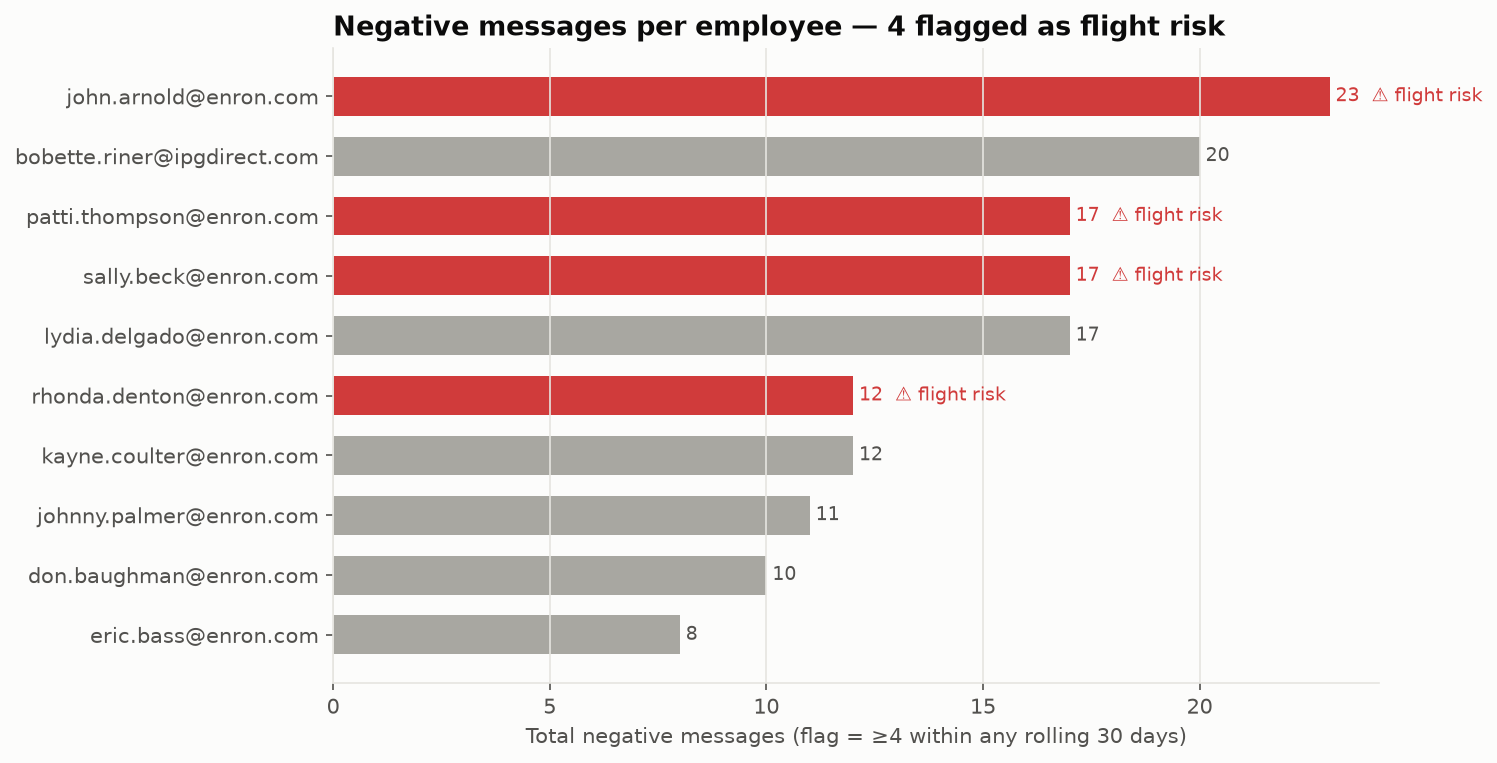

In [23]:
# robustness check: compare with a naive calendar-month count (>= 4 negatives in the same month)
naive = scores.loc[scores.negative_count >= 4, "employee"].unique()
print("Calendar-month method would flag:", len(naive))
print("Only caught by the rolling window:", sorted(set(risk.employee) - set(naive)))
display(Image(viz.flight_risk_chart(df, risk)))

### Observations

In [24]:
show(findings.flight_md(scores, risk, df['from'].nunique()))

* **4 of 10 employees are flagged** (max negatives in one 30-day window): john.arnold@enron.com (4), patti.thompson@enron.com (4), rhonda.denton@enron.com (4), sally.beck@enron.com (4).
* A calendar-month count would flag only **2**. The rolling window adds **rhonda.denton@enron.com and sally.beck@enron.com**, whose negative bursts straddle a month boundary. This is why the brief specifies a rolling window.
* The flag is deliberately independent of the score: an employee with a high long-run score can still have a short burst of negativity. Every qualifying window is listed in `data/processed/flight_risk_windows.csv` so that each flag can be reviewed manually.

## 7. Task 6 — Predictive modeling (linear regression)

**Target:** the monthly sentiment score of an employee (Task 3). **Unit:** one row per employee-month.

**Features** — chosen as behavioural signals that may influence sentiment and that are *not* computed from the sentiment labels (to avoid leakage):

| Feature | Rationale |
|---|---|
| `message_count` | engagement / activity level in the month |
| `avg_char_length`, `avg_word_count`, `total_words` | how much the employee writes |
| `active_days` | how many distinct days the employee communicated |
| `avg_exclamations`, `avg_questions` | emotional intensity / uncertainty |
| `prev_month_score` | sentiment momentum (last month's score, 0 if silent) |
| `month_index` | time trend |

**Model:** `StandardScaler → LinearRegression` (scikit-learn), 80/20 train/test split (`random_state=42`), 5-fold cross-validation,
compared against a mean-only baseline. Metrics: R², MAE, RMSE.

In [25]:
data = modeling.build_features(df, scores)
data[modeling.FEATURES + [modeling.TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
message_count,240.0,9.13,5.73,1.0,4.75,9.00,12.00,27.00
avg_char_length,240.0,231.76,100.44,0.0,170.48,224.04,275.26,706.00
avg_word_count,240.0,40.20,17.61,0.0,29.88,38.84,47.74,126.00
total_words,240.0,371.20,261.41,0.0,142.50,355.00,535.75,1211.00
active_days,240.0,7.52,4.25,1.0,4.00,7.00,11.00,20.00
avg_exclamations,240.0,0.20,0.24,0.0,0.00,0.14,0.29,1.54
avg_questions,240.0,0.93,1.92,0.0,0.08,0.25,0.54,16.65
prev_month_score,240.0,1.48,1.83,-3.0,0.00,1.00,3.00,8.00
month_index,240.0,11.50,6.94,0.0,5.75,11.50,17.25,23.00
monthly_score,240.0,1.55,1.82,-3.0,0.00,1.00,3.00,8.00


In [26]:
data[modeling.FEATURES + [modeling.TARGET]].corr()[modeling.TARGET].drop(modeling.TARGET).sort_values().round(3)

avg_questions       0.045
avg_word_count      0.048
prev_month_score    0.054
avg_char_length     0.055
month_index         0.128
avg_exclamations    0.151
total_words         0.473
active_days         0.501
message_count       0.518
Name: monthly_score, dtype: float64

In [27]:
result = modeling.train_and_evaluate(data)
trend = modeling.company_trend(scores)
modeling.save_outputs(result, trend)
pd.Series(result["metrics"]).round(3)

n_rows                240.000
n_train               192.000
n_test                 48.000
train_r2                0.254
test_r2                 0.355
test_mae                1.257
test_rmse               1.741
baseline_test_mae       1.671
baseline_test_rmse      2.169
cv5_r2_mean             0.210
cv5_r2_std              0.116
intercept               1.547
dtype: float64

,feature,std_coefficient
0,avg_char_length,-0.389
1,message_count,0.315
2,avg_word_count,0.296
3,active_days,0.288
4,avg_exclamations,0.260
5,total_words,0.215
6,month_index,0.186
7,avg_questions,-0.088
8,prev_month_score,0.063


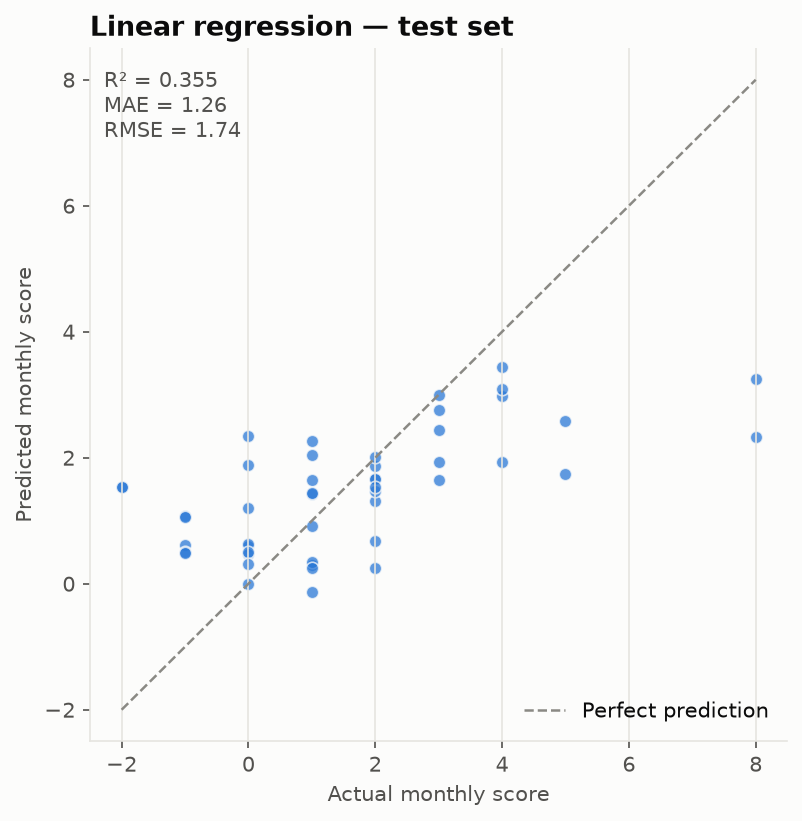

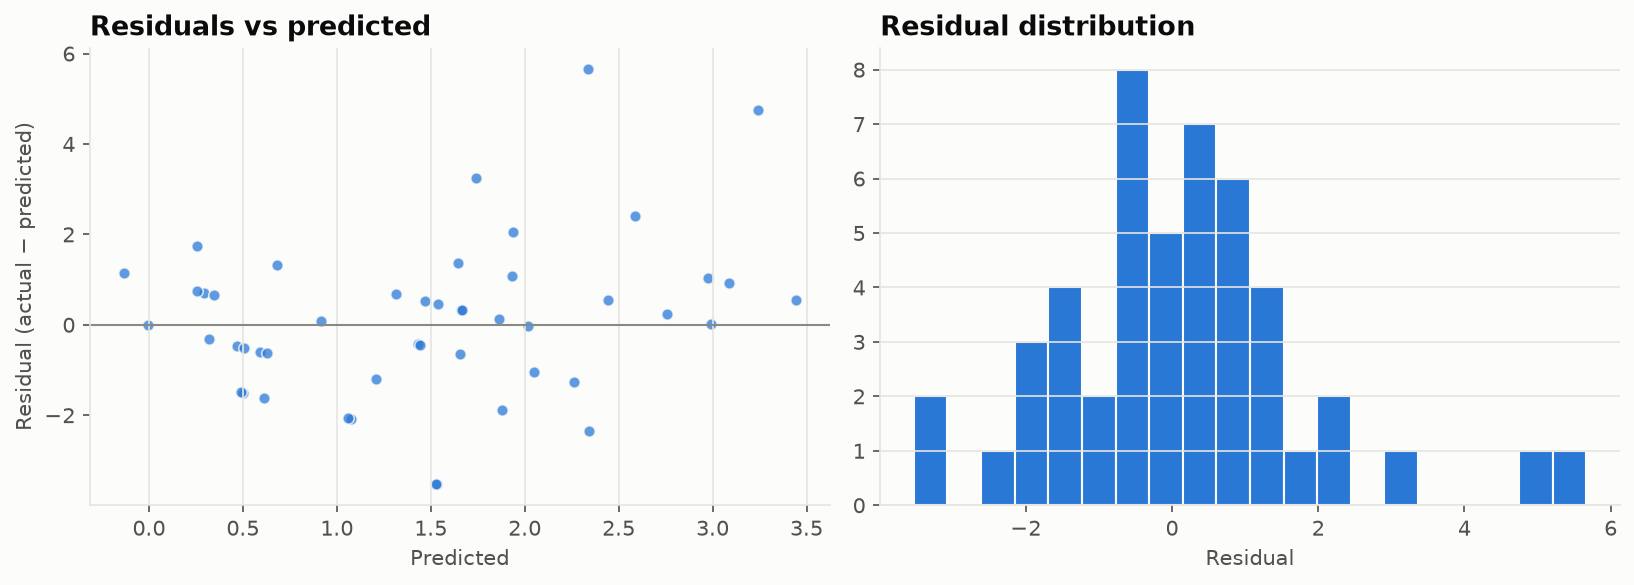

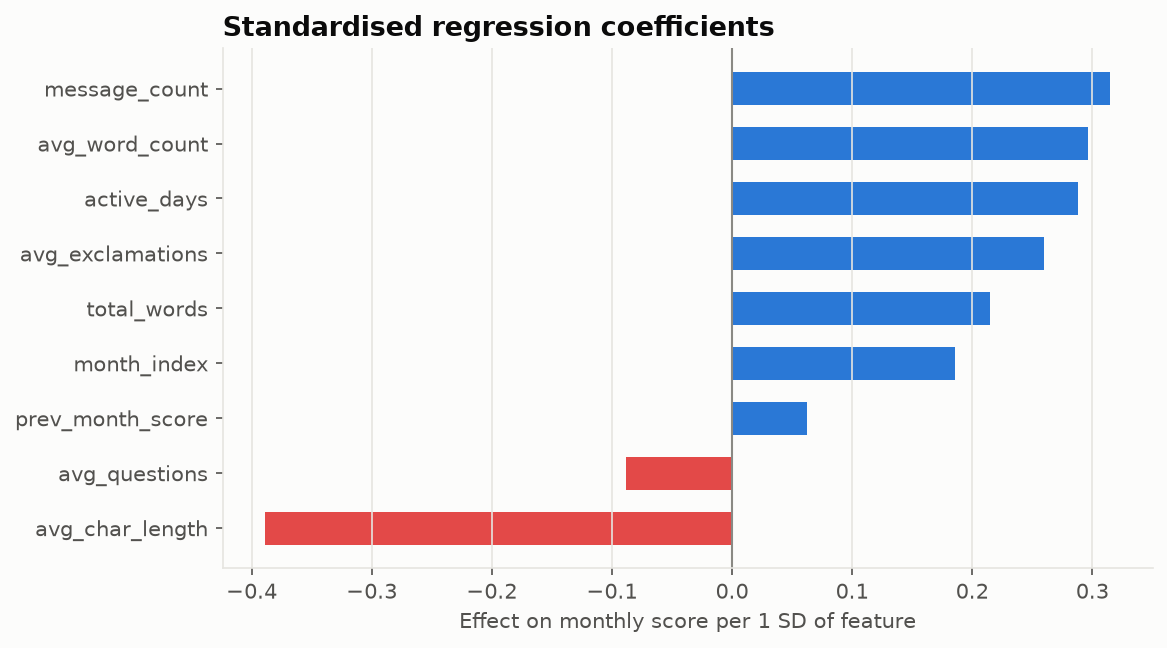

In [28]:
display(result["coefficients"].round(3))
display(Image(viz.model_pred_vs_actual(result["y_test"], result["y_pred"], result["metrics"])))
display(Image(viz.model_residuals(result["y_test"], result["y_pred"])))
display(Image(viz.model_coefficients(result["coefficients"])))

Company-wide trend: +0.0336 score points per month (R2=0.301)


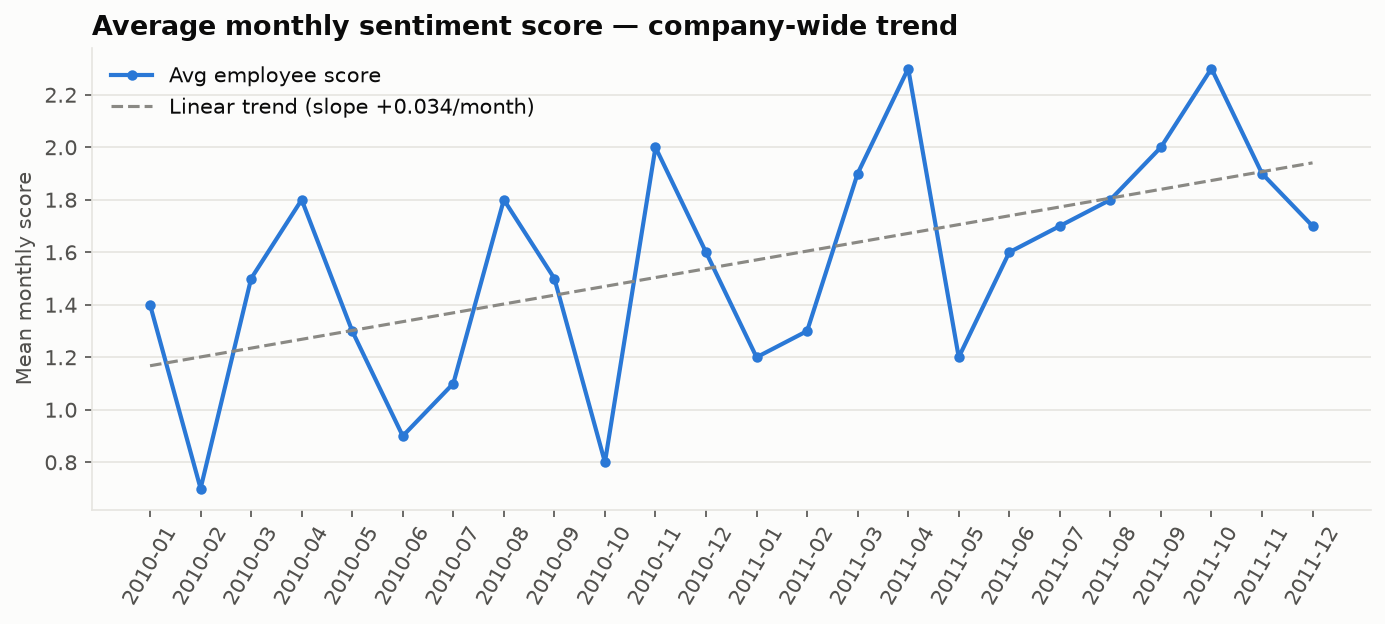

In [29]:
print(f"Company-wide trend: {trend['slope_per_month']:+.4f} score points per month (R2={trend['r2']:.3f})")
display(Image(viz.company_trend_chart(trend)))

### Model interpretation

In [30]:
show(findings.model_md(result['metrics'], result['coefficients'], trend, df))

* **Performance:** test R² = **0.35**, MAE = **1.26**, RMSE = **1.74**, against a mean-only baseline with MAE 1.67 / RMSE 2.17. 5-fold cross-validation R² = 0.21 ± 0.12. Train R² is 0.25, so some overfitting is present.
* **Strongest driver:** `avg_char_length` (standardised coefficient -0.39).
* `prev_month_score` is positive (sentiment momentum); the company-wide average score trends +0.034 points per month.
* **Significance:** the model describes and forecasts the *level* of the score well. Because volume drives much of it, a volume-normalised target (average score per message) would better isolate tone, and is the natural next iteration.

## 8. Summary and recommendations
The same generated summary is written into `README.md` by `run_pipeline.py`.

In [31]:
summary_md = findings.readme_summary_md(df, raw, scores, rankings, risk, windows, result['metrics'], trend)
show(summary_md)

> Dataset: 2,191 messages · 10 employees · Jan 2010 – Dec 2011 (24 months). Labeling: a RoBERTa transformer (cardiffnlp/twitter-roberta-base-sentiment-latest).

**Sentiment:** 520 Positive (23.7%) · 1,524 Neutral (69.6%) · 147 Negative (6.7%)

### Top three positive and negative employees (latest month, 2011-12)

| Rank | Top positive | Score | Top negative | Score |
|---|---|---|---|---|
| 1 | kayne.coulter@enron.com | 4 | bobette.riner@ipgdirect.com | 0 |
| 2 | eric.bass@enron.com | 3 | don.baughman@enron.com | 1 |
| 3 | patti.thompson@enron.com | 3 | john.arnold@enron.com | 1 |

Ties are broken alphabetically. Rankings for all months are in `data/processed/monthly_rankings.csv` and in the notebook. Across all 24 months, **bobette.riner@ipgdirect.com** made the monthly top-3 positive most often (12 months), and **don.baughman@enron.com** the top-3 negative most often (12 months).

### Employees flagged as flight risk (≥ 4 negative messages within any rolling 30 days)

| Employee | Max negatives in 30 days | First flagged window |
|---|---|---|
| john.arnold@enron.com | 4 | 2010-06-06 → 2010-07-05 |
| patti.thompson@enron.com | 4 | 2010-10-04 → 2010-11-02 |
| rhonda.denton@enron.com | 4 | 2010-12-24 → 2011-01-22 |
| sally.beck@enron.com | 4 | 2010-12-15 → 2011-01-13 |

A calendar-month count would catch only 2 of these 4. The rolling window also finds rhonda.denton@enron.com and sally.beck@enron.com, whose bursts of negativity cross a month boundary.

### Predictive model

Linear regression of the monthly score achieves **test R² = 0.35**, MAE = 1.26 and RMSE = 1.74. A mean-only baseline scores MAE = 1.67 and RMSE = 2.17. 5-fold cross-validation gives R² = 0.21 ± 0.12. The company-wide average score trends +0.034 points per month.

### Key insights and recommendations

1. Overall sentiment is mixed (23.7% positive). The risk signal comes from short **bursts** of negativity rather than persistently negative employees.
2. Prioritise check-ins with **john.arnold@enron.com** (strongest burst: 4 negatives in 30 days from 2010-06-06) and **don.baughman@enron.com** (top-3 negative in 12 of 24 months).
3. Use the **rolling-window** flag operationally. It catches 2 employee(s) a monthly report would miss.
4. Monthly scores are volume-driven. Report the average score per message alongside the sum, so quiet employees are not mislabelled as disengaged.
5. Review each flagged window's messages before acting: automated sentiment is a screening tool, not a verdict.